## 파인튜닝과 LoRA


In [1]:
import numpy as np


### LLM을 파인튜닝하는 목적

파인튜닝은 사전학습된 모델을 목적에 맞는 데이터로 추가 학습해 가중치를 조정하는 과정이다.
새로운 지식과 용어를 학습시키거나, 특정 작업의 수행 능력을 개선하거나, 응답의 형식과 표현을 일관되게 만드는 데 사용한다.

RAG(Retrieval-Augmented Generation)는 질문과 관련된 외부 자료를 검색해 모델의 입력에 함께 제공하는 방식이다.
같은 지식도 파인튜닝으로 가중치에 학습시키거나, RAG로 답변 시점의 입력에 제공할 수 있다.

| 방법 | 할 수 있는 일 | 장점 | 단점·한계 |
| --- | --- | --- | --- |
| RAG | 외부 문서 기반 질문·응답, 최신 정보와 내부 자료 활용 | 문서 갱신으로 정보를 반영하기 쉽고, 답변의 근거 문서를 제시할 수 있음 | 검색한 자료의 품질과 누락에 영향을 받으며, 검색과 늘어난 입력에 시간·비용이 듦 |
| 파인튜닝 | 새로운 지식·용어 학습, 분류·요약 등 작업 수행 개선, 응답 형식·표현 조정 | 여러 입력에서 원하는 작업 기준과 응답 방식을 더 일관되게 따르도록 조정할 수 있음 | 학습 데이터와 연산 자원이 필요하고, 학습한 지식의 갱신에는 추가 학습이 필요함. 사실을 정확히 재현하는지도 평가해야 함 |

주로 최신 정보나 특정 문서의 내용을 근거로 답해야 할 때는 RAG를 먼저 고려한다.
파인튜닝한 모델에 RAG를 함께 적용해, 학습한 지식·응답 방식과 검색한 문서를 함께 활용할 수도 있다.

### 파인튜닝의 가치가 큰 경우

프롬프트에 작업 지시와 답변 예시를 넣어 여러 입력에서 원하는 품질과 형식을 충족하면 그 방식을 사용한다.
작업에 맞춘 추가 학습이 필요하면 파인튜닝을 고려한다.

- 특정 작업의 성능을 개선할 때: 지시와 예시를 조정해도 분류·정보 추출·요약 등에서 같은 유형의 오류가 반복된다면, 올바른 처리 사례를 학습시켜 정확도와 일관성을 개선할 수 있다.
- 작은 모델을 특정 작업에 특화할 때: 범위가 명확한 작업에 맞춰 작은 모델을 학습시키고, 요구 성능을 충족하는지 평가한다. 목표를 충족하면 더 큰 모델을 사용하는 것보다 추론 비용과 지연 시간을 줄일 수 있다.
- 동일한 작업을 대규모로 반복할 때: 매번 전달하던 규칙과 예시를 학습시켜, 같은 품질을 유지하면서 입력 토큰을 줄일 수 있다. 문맥 창의 최대 길이는 유지되지만, 질문과 참고 문서에 사용할 토큰 여유가 늘어난다. 현재 질문과 매번 달라지는 정보는 계속 입력으로 제공해야 한다.

효과는 학습에 쓰지 않은 사례로 확인하고, 비용 절감은 예상 호출량에 따른 추론 비용과 데이터 준비·학습 비용을 함께 비교한다.


## SFT로 응답 학습하기

입력과 모범 응답을 짝지은 데이터로 언어 모델을 조정하는 방법을 SFT(Supervised Fine-Tuning, 지도 파인튜닝)라고 한다.

지시와 질문을 입력 문맥으로 사용하고, 모범 응답에만 손실을 계산하는 방식으로 학습할 수 있다.
응답의 종료 토큰까지 학습 대상에 포함해, 원하는 응답을 생성하고 마치도록 가중치를 조정한다.


## LoRA로 학습 파라미터 줄이기

CNN의 전이학습에서는 사전학습된 백본에 새 분류 헤드를 붙여 학습하고, 필요하면 백본도 함께 조정한다.
언어 모델의 질문·응답 학습에서는 기존의 다음 토큰 예측 구조를 유지하면서 원하는 응답을 생성하도록 조정한다.

LLM은 파라미터가 수십억 개 이상인 경우가 많다.
기존 가중치 전체를 갱신하는 전체 파인튜닝에서는 기울기와 옵티마이저의 갱신 정보도 저장해야 하므로, 많은 파라미터가 큰 메모리 부담으로 이어진다.

LoRA(Low-Rank Adaptation)는 기본 가중치를 고정하고, 선택한 층에 작은 행렬 두 개를 추가해 가중치 변화량을 학습하는 방법이다.
추가한 학습 가능한 부분을 어댑터(adapter)라고 한다.
SFT의 학습 목표를 유지하면서, 갱신할 파라미터를 LoRA 어댑터로 제한할 수 있다.
응답 손실을 줄이도록 어댑터를 갱신하면, 기본 가중치를 유지하면서도 모델의 출력을 바꿀 수 있다.


### LoRA의 출력 계산

LoRA를 적용할 선형층의 입력 $x$를 열벡터로 쓰고 편향을 생략하면, 기본 출력은 $Wx$다.

가중치 변화량 $\Delta W$를 행렬 하나로 직접 학습하면, 기본 가중치 $W$와 같은 수의 값을 학습해야 한다.
LoRA는 이 변화량을 두 작은 행렬의 곱으로 표현해 학습할 값의 수를 줄인다.

행렬 A는 입력을 작은 중간 차원 $r$로 바꾸고, 행렬 B는 이를 원래 출력 차원으로 바꾼다.
$r$을 충분히 작게 정하면 A·B의 원소 수 합이 $W$의 원소 수보다 작아지면서, 두 행렬의 곱은 $W$와 같은 크기가 된다.

행렬의 랭크(rank)는 열벡터들이 만드는 서로 독립적인 방향의 수다.
B에는 열벡터가 $r$개 있고, $BA$의 각 열은 이 열벡터들을 조합해 만들어진다.
따라서 $BA$가 표현할 수 있는 독립적인 방향은 최대 $r$개이며, 실제 랭크는 A·B의 값에 따라 더 작을 수 있다.
예를 들어 $r=1$이면 $BAx$는 항상 B의 한 열벡터에 숫자를 곱한 결과이므로, 표현할 수 있는 방향이 최대 하나다.
이처럼 작은 $r$로 변화량의 랭크를 제한하는 것이 저랭크이며, 학습할 값과 표현할 수 있는 변화의 범위를 함께 줄인다.

$\alpha$는 추가 변화량에 곱할 배율을 정하는 설정값이며, 실제 배율은 $\alpha/r$이다.
예를 들어 $\alpha=2r$이면 $BAx$에 2를 곱해 기본 출력에 더한다.

$$
h=Wx+\frac{\alpha}{r}BAx,\qquad \Delta W=\frac{\alpha}{r}BA
$$

| 기호 | 모양 | 역할 |
| --- | --- | --- |
| $x$ | $(d_{\mathrm{in}},)$ | 선택한 층에 들어오는 입력 벡터 |
| $W$ | $(d_{\mathrm{out}},d_{\mathrm{in}})$ | 동결한 기본 가중치 |
| $A$ | $(r,d_{\mathrm{in}})$ | 입력을 작은 중간 차원으로 변환 |
| $B$ | $(d_{\mathrm{out}},r)$ | 중간 표현을 출력 차원으로 변환 |
| $\alpha/r$ | 스칼라 | 변화량에 곱하는 배율 |

$d_{\mathrm{in}}$과 $d_{\mathrm{out}}$은 입력·출력 크기다.
$Ax$는 $r$차원, $B(Ax)$는 $d_{\mathrm{out}}$차원이므로 기본 출력과 더할 수 있다.
LoRA로 달라진 출력 $h$는 이후 층의 계산을 거쳐 다음 토큰의 예측에 영향을 준다.


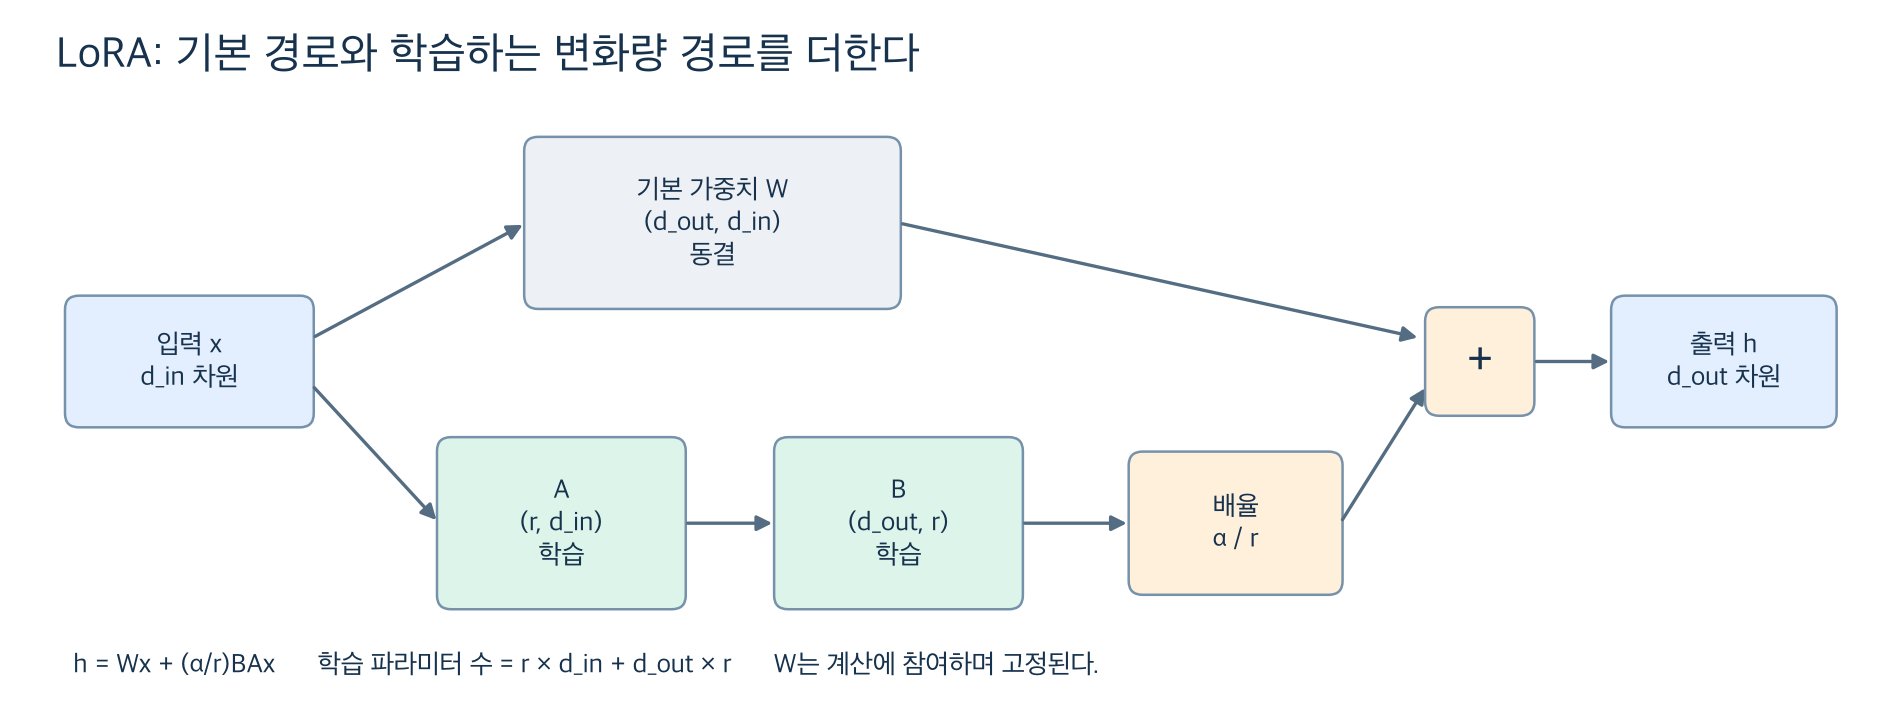


### rank와 학습 파라미터 수

입력 크기가 $d_{\mathrm{in}}$, 출력 크기가 $d_{\mathrm{out}}$인 선형층을 생각하자.
편향을 제외한 전체 가중치와 LoRA의 학습 파라미터 수는 다음과 같다.

$$
N_{\mathrm{full}}=d_{\mathrm{out}}d_{\mathrm{in}},\qquad
N_{\mathrm{LoRA}}=r(d_{\mathrm{in}}+d_{\mathrm{out}})
$$

$1024\times1024$ 가중치는 1,048,576개다.
rank 8이면 $8\times1024+1024\times8=16,384$개를 학습하므로 이 층의 전체 가중치 수의 1.5625%다.
rank를 두 배로 늘리면 A·B의 파라미터 수는 두 배가 되지만, 모델 전체의 메모리와 성능은 실제 실행에서 따로 측정한다.


In [2]:
d_in, d_out, r = 1024, 1024, 8  # 입력 크기, 출력 크기, 중간 크기

# zeros는 지정한 모양을 0으로 채운다. 여기서는 배열의 크기와 원소 수를 확인한다.
W = np.zeros((d_out, d_in))
A = np.zeros((r, d_in))
B = np.zeros((d_out, r))

# shape은 배열의 모양, size는 전체 원소 수다.
print("W, A, B의 모양:", W.shape, A.shape, B.shape)
print("전체 가중치 수:", W.size)
print("LoRA 학습 파라미터 수:", A.size + B.size)
print("전체 대비 비율:", f"{(A.size + B.size) / W.size:.4%}")


W, A, B의 모양: (1024, 1024) (8, 1024) (1024, 8)
전체 가중치 수: 1048576
LoRA 학습 파라미터 수: 16384
전체 대비 비율: 1.5625%


## 양자화와 QLoRA

양자화는 가까운 수치를 대표값으로 묶고, 대표값의 번호를 적은 비트로 저장하는 방법이다.
모델의 가중치를 양자화해 저장하면 저장량이 줄어들며, 이 과정에서 근사 오차가 생길 수 있다.

가중치 원소 수가 $N$, 저장 비트 수가 $b$라면 가중치 값 자체의 크기는 대략 $Nb/8$바이트다.


QLoRA(Quantized LoRA)는 기본 모델의 가중치를 양자화해 저장하고 고정한 채, LoRA 어댑터를 학습하는 방법이다.
양자화는 기본 가중치의 저장량을 줄이고, LoRA는 학습할 파라미터 수를 줄인다.

실제 학습에는 양자화의 부가 정보, 어댑터, 기울기, 옵티마이저의 갱신 정보, 중간 계산 결과를 저장하는 메모리도 필요하다.
